**Name:** Vikrant Haral     
**Division:** E        
**Batch:** E1              
**Roll No.:** TY-319   
**PRN:** 202401040332

---

**Practical Assignment 5: Ensemble Learning and Performance Evaluation**

---

**1. Aim:**
To implement and evaluate Stacking, AdaBoost, and Voting ensemble learning techniques and compare their performance with individual machine learning classifiers using appropriate classification metrics.

---

**2.Objectives:**

1. To understand the concept and working of ensemble learning techniques.
2. To implement individual machine learning classification algorithms.
3. To implement Stacking Ensemble using a meta-classifier.
4. To implement AdaBoost Ensemble using weak learners.
5. To implement Voting Ensemble using majority voting.
6. To evaluate models using Accuracy, Precision, Recall, and F1-score.
7. To compare individual and ensemble classifiers and identify the most suitable model.

---


**3.Theory:**

Ensemble Learning is a machine learning technique that combines multiple individual models to produce a more reliable and accurate prediction.

Instead of depending on a single classifier, ensemble methods combine the outputs of different models to improve predictive performance, stability, and generalization.

**3.1. Stacking Ensemble:**

Stacking combines predictions from multiple base classifiers using another machine learning model called a meta-classifier.

The base classifiers generate predictions, which are used as input features for the meta-classifier to produce the final prediction.

**3.2. AdaBoost Ensemble:**

Adaptive Boosting (AdaBoost) is a boosting technique that trains weak learners sequentially. It gives more importance to incorrectly classified observations in subsequent iterations.

The final prediction is obtained by combining the weighted predictions of all weak learners.

**3.3. Voting Ensemble:**

Voting combines predictions from multiple independent classifiers.

In Hard Voting, each classifier votes for a class, and the class receiving the majority of votes becomes the final prediction.

**3.4. Performance Evaluation Metrics:**

- Accuracy: Measures the proportion of correctly classified observations.
- Precision: Measures the proportion of correctly predicted positive observations.
- Recall: Measures the proportion of actual positive observations correctly identified.
- F1-score: Harmonic mean of Precision and Recall.

For multiclass classification, macro and weighted averages are used to evaluate performance across all classes.





In [ ]:

# Import basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset handling
import zipfile
from pathlib import Path
from google.colab import files

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Individual classifiers
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

# Ensemble classifiers
from sklearn.ensemble import (
    StackingClassifier,
    AdaBoostClassifier,
    VotingClassifier
)

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings('ignore')

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (9, 5)

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:
# Upload the Dry Bean Dataset (ZIP or Excel file)

uploaded = files.upload()

file_name = next(iter(uploaded))

extract_path = "/content/DryBeanData"
Path(extract_path).mkdir(parents=True, exist_ok=True)

if file_name.endswith('.zip'):

    with zipfile.ZipFile(file_name, 'r') as zip_ref:
        zip_ref.extractall(extract_path)

    excel_files = list(Path(extract_path).rglob("*.xlsx"))

elif file_name.endswith('.xlsx'):

    excel_path = Path(extract_path) / file_name

    with open(file_name, 'rb') as source:
        with open(excel_path, 'wb') as destination:
            destination.write(source.read())

    excel_files = [excel_path]

else:
    raise ValueError("Please upload a ZIP or XLSX file.")

if not excel_files:
    raise FileNotFoundError("Excel dataset not found.")

print("Dataset uploaded successfully!")
print("Excel file:", excel_files[0].name)

Saving Dry_Bean_Dataset.xlsx to Dry_Bean_Dataset (4).xlsx
Dataset uploaded successfully!
Excel file: Dry_Bean_Dataset (4).xlsx


In [ ]:

# Load the Excel dataset
df = pd.read_excel(excel_files[0])

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst Five Records:")
display(df.head())


Dataset loaded successfully!
Dataset Shape: (13611, 17)

First Five Records:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [ ]:

# Display dataset information
print("DATASET INFORMATION")
print("=" * 45)

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nStatistical Summary:")
display(df.describe().round(2))


DATASET INFORMATION

Number of Rows: 13611
Number of Columns: 17

Column Names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Data Types:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRation       float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class               object
dtype: object

Statistical Summary:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.00,13611.0,13611.00,13611.00
mean,53048.28,855.28,320.14,202.27,1.58,0.75,53768.20,253.06,0.75,0.99,0.87,0.80,0.01,0.0,0.64,1.00
std,29324.10,214.29,85.69,44.97,0.25,0.09,29774.92,59.18,0.05,0.00,0.06,0.06,0.00,0.0,0.10,0.00
min,20420.00,524.74,183.60,122.51,1.02,0.22,20684.00,161.24,0.56,0.92,0.49,0.64,0.00,0.0,0.41,0.95
25%,36328.00,703.52,253.30,175.85,1.43,0.72,36714.50,215.07,0.72,0.99,0.83,0.76,0.01,0.0,0.58,0.99
50%,44652.00,794.94,296.88,192.43,1.55,0.76,45178.00,238.44,0.76,0.99,0.88,0.80,0.01,0.0,0.64,1.00
75%,61332.00,977.21,376.50,217.03,1.71,0.81,62294.00,279.45,0.79,0.99,0.92,0.83,0.01,0.0,0.70,1.00
max,254616.00,1985.37,738.86,460.20,2.43,0.91,263261.00,569.37,0.87,0.99,0.99,0.99,0.01,0.0,0.97,1.00


In [ ]:

# Check missing values
print("Missing Values:")
display(df.isnull().sum())

# Check duplicate records
duplicates = df.duplicated().sum()

print("\nTotal Duplicate Records:", duplicates)

# Check target distribution
print("\nTarget Class Distribution:")
display(df['Class'].value_counts())


Missing Values:


,0
Area,0
Perimeter,0
MajorAxisLength,0
MinorAxisLength,0
AspectRation,0
Eccentricity,0
ConvexArea,0
EquivDiameter,0
Extent,0
Solidity,0



Total Duplicate Records: 68

Target Class Distribution:


,count
Class,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522


**Exploratory Data Analysis (EDA)**

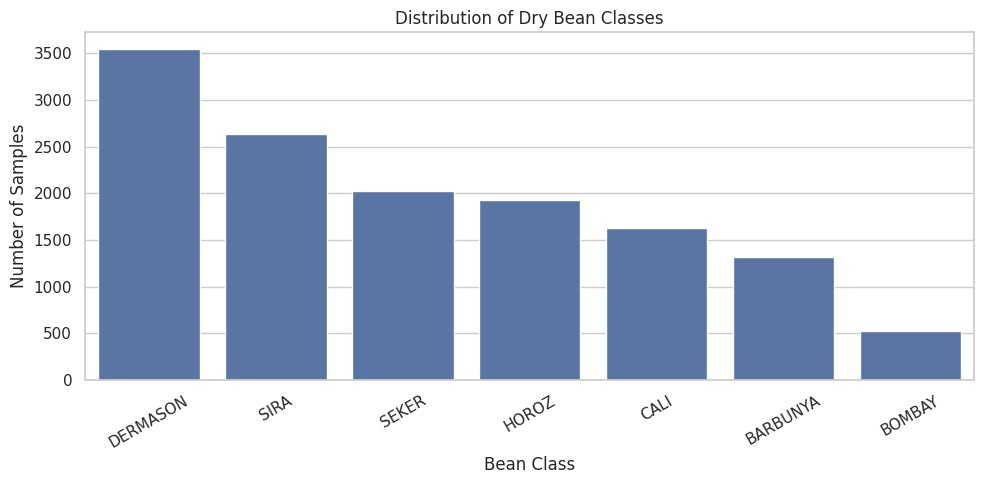

In [ ]:

# Distribution of target classes
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='Class',
    order=df['Class'].value_counts().index
)

plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


**Feature distribution**

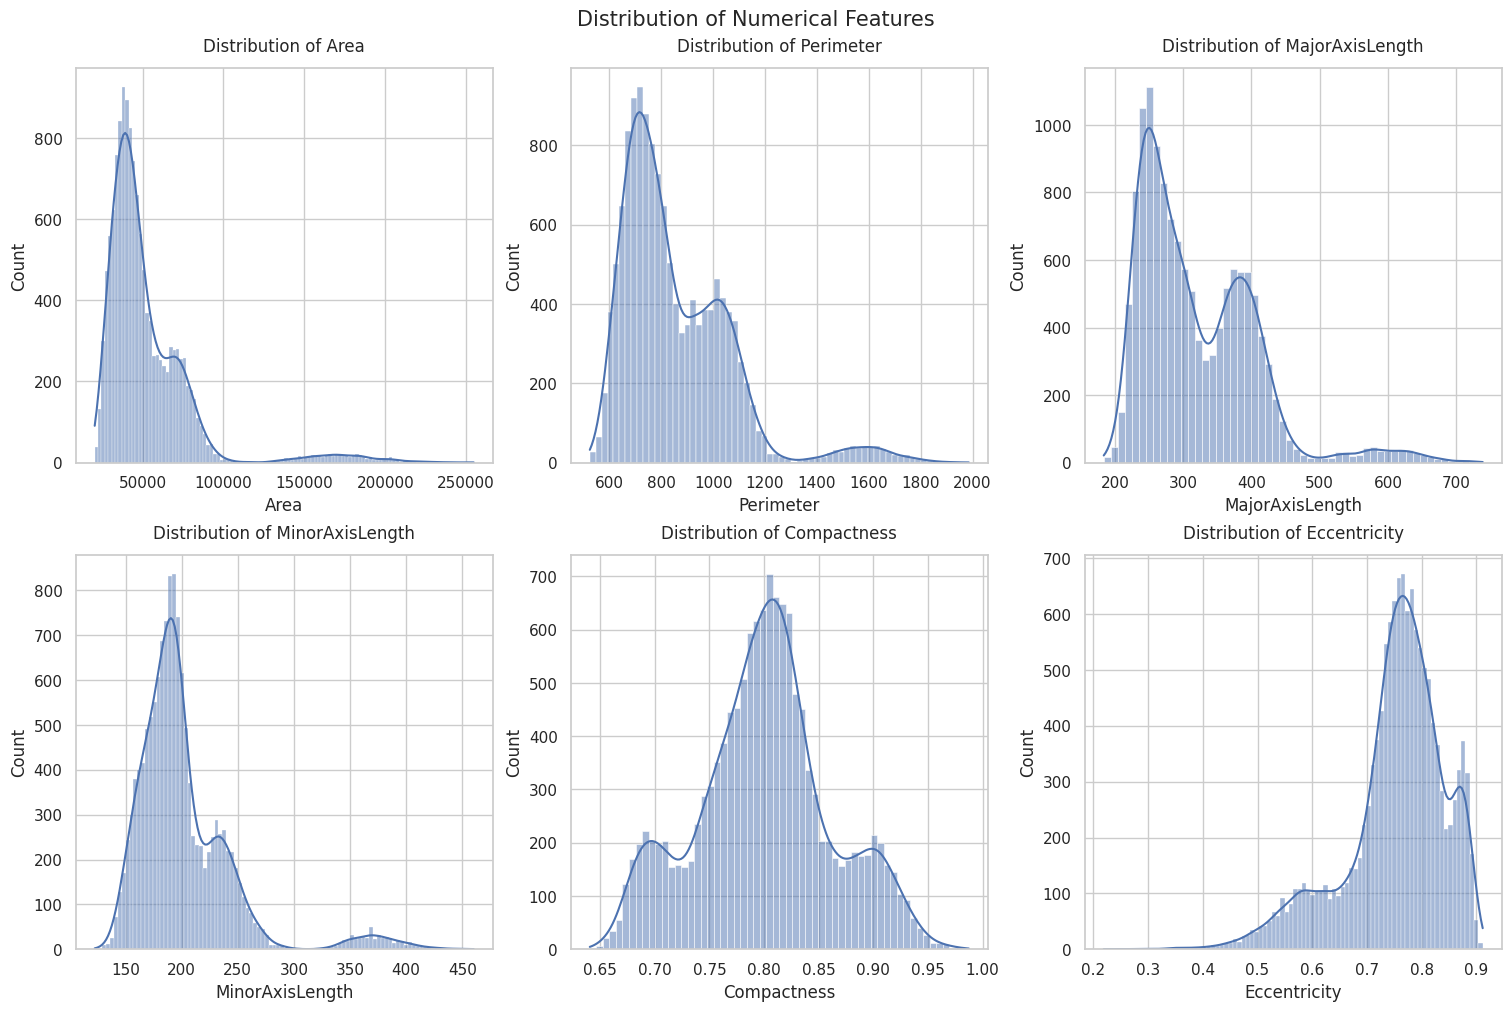

In [ ]:
# Visualize important numerical features

selected_features = [
    'Area',
    'Perimeter',
    'MajorAxisLength',
    'MinorAxisLength',
    'Compactness',
    'Eccentricity'
]

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 10),
    constrained_layout=True
)

for feature, ax in zip(selected_features, axes.flatten()):
    sns.histplot(
        data=df,
        x=feature,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {feature}", pad=12)

fig.suptitle("Distribution of Numerical Features", fontsize=15)

plt.show()
plt.close(fig)

**Correlation heatmap**

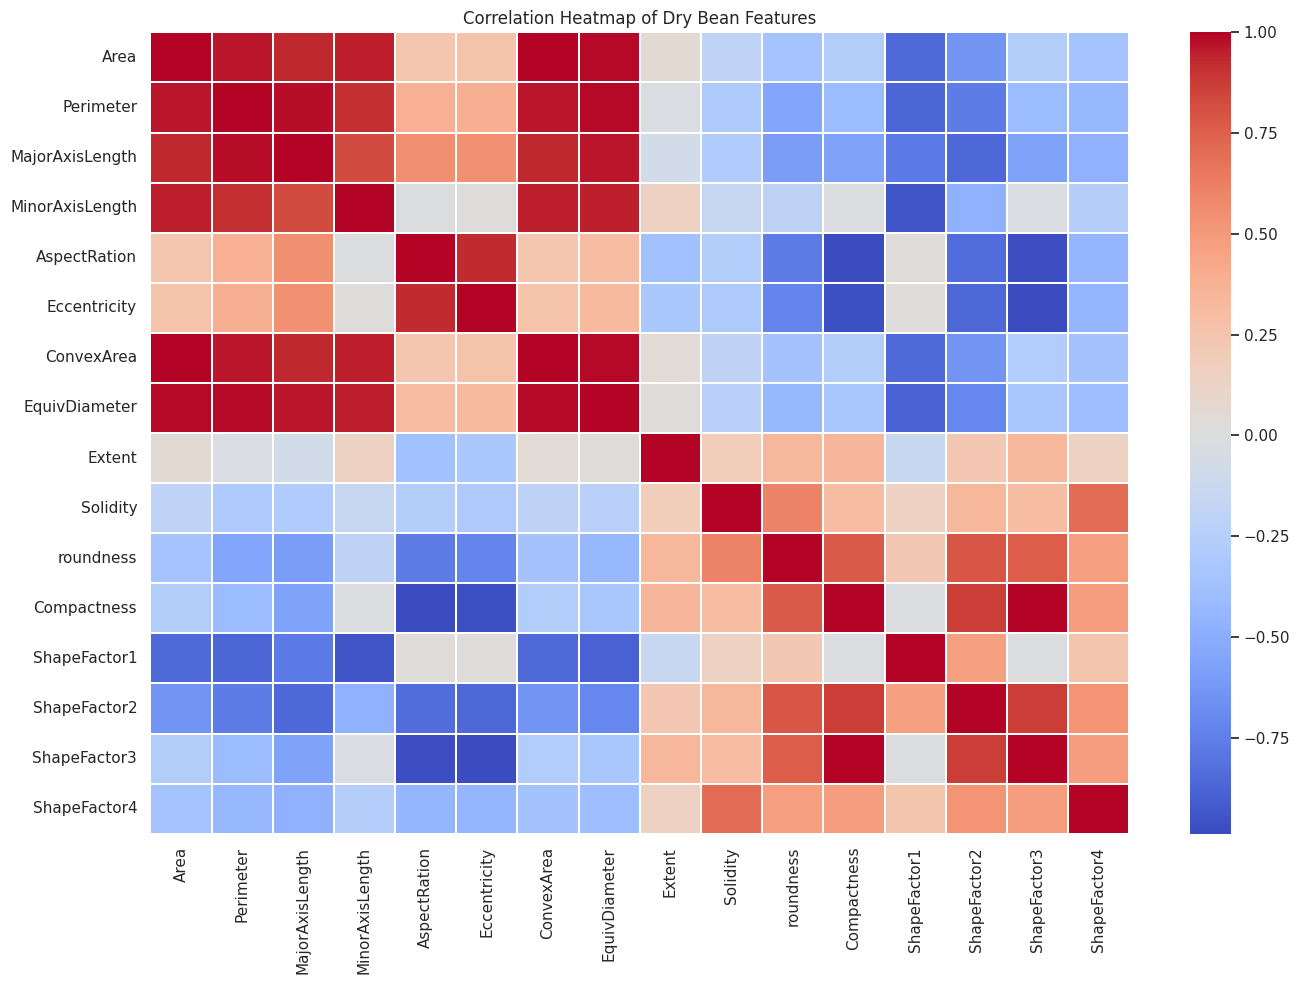

In [ ]:

# Calculate correlation between numerical features
correlation = df.drop(columns=['Class']).corr()

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation,
    cmap='coolwarm',
    annot=False,
    linewidths=0.3
)

plt.title("Correlation Heatmap of Dry Bean Features")
plt.tight_layout()
plt.show()


**Observation:**

 The correlation heatmap helps identify relationships between numerical features. Highly correlated features indicate that some measurements may provide overlapping information.

In [ ]:

# Separate independent and dependent variables
X = df.drop(columns=['Class'])
y = df['Class']

# Display dimensions
print("Independent Variables Shape:", X.shape)
print("Dependent Variable Shape:", y.shape)

print("\nTarget Classes:")
print(sorted(y.unique()))

# Check for missing values
print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())


Independent Variables Shape: (13611, 16)
Dependent Variable Shape: (13611,)

Target Classes:
['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']

Missing values in X: 0
Missing values in y: 0


**Explanation:**
- Independent variables (X): 16 numerical bean characteristics.
- Dependent variable (y): Class of the dry bean.
- The target variable contains seven categories.
We will use StandardScaler inside pipelines for distance-based and linear models. This ensures that scaling is learned only from training data and avoids data leakage.

In [ ]:

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Samples:", len(X_train))
print("Testing Samples:", len(X_test))


Training Data Shape: (10888, 16)
Testing Data Shape: (2723, 16)

Training Samples: 10888
Testing Samples: 2723


**Define base classifiers**

In [ ]:

# Decision Tree Classifier
dt_model = DecisionTreeClassifier(
    max_depth=12,
    random_state=42
)

# Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# K-Nearest Neighbors Classifier
knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5))
])

# Logistic Regression Classifier
lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('lr', LogisticRegression(
        max_iter=3000,
        random_state=42
    ))
])

print("Four base classifiers defined successfully!")


Four base classifiers defined successfully!


**Train individual classifiers**

In [ ]:

# Store individual models
base_models = {
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'KNN': knn_model,
    'Logistic Regression': lr_model
}

# Train all base classifiers
for name, model in base_models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")


Decision Tree trained successfully!
Random Forest trained successfully!
KNN trained successfully!
Logistic Regression trained successfully!


**Evaluate individual classifiers**

In [ ]:

# Function to calculate classification metrics
def evaluate_model(name, model, X_test, y_test):

    y_pred = model.predict(X_test)

    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(
            y_test, y_pred, average='weighted', zero_division=0
        ),
        'Recall': recall_score(
            y_test, y_pred, average='weighted', zero_division=0
        ),
        'F1-Score': f1_score(
            y_test, y_pred, average='weighted', zero_division=0
        )
    }

# Evaluate individual classifiers
results = []

for name, model in base_models.items():
    results.append(
        evaluate_model(name, model, X_test, y_test)
    )

base_results = pd.DataFrame(results)

print("INDIVIDUAL CLASSIFIER PERFORMANCE")
display(base_results.round(4))


INDIVIDUAL CLASSIFIER PERFORMANCE


,Model,Accuracy,Precision,Recall,F1-Score
0,Decision Tree,0.9023,0.9026,0.9023,0.9024
1,Random Forest,0.9199,0.9199,0.9199,0.9198
2,KNN,0.9166,0.9174,0.9166,0.9168
3,Logistic Regression,0.9214,0.9222,0.9214,0.9216


**Implementation of ensemble learning techniques:**

**Stacking Ensemble Classifier**

In [ ]:

# Define base estimators for Stacking
stack_estimators = [
    ('dt', DecisionTreeClassifier(
        max_depth=12,
        random_state=42
    )),

    ('rf', RandomForestClassifier(
        n_estimators=150,
        random_state=42,
        n_jobs=-1
    )),

    ('knn', Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=5))
    ]))
]

# Define Stacking Classifier
stacking_model = StackingClassifier(
    estimators=stack_estimators,
    final_estimator=LogisticRegression(max_iter=3000),
    cv=5,
    n_jobs=-1
)

# Train the Stacking model
stacking_model.fit(X_train, y_train)

print("Stacking Ensemble trained successfully!")


Stacking Ensemble trained successfully!


**Evaluate Stacking Ensemble**

In [ ]:

# Predict using Stacking
y_pred_stack = stacking_model.predict(X_test)

# Calculate performance metrics
stack_accuracy = accuracy_score(y_test, y_pred_stack)
stack_precision = precision_score(
    y_test, y_pred_stack, average='weighted', zero_division=0
)
stack_recall = recall_score(
    y_test, y_pred_stack, average='weighted', zero_division=0
)
stack_f1 = f1_score(
    y_test, y_pred_stack, average='weighted', zero_division=0
)

print("STACKING ENSEMBLE PERFORMANCE")
print("=" * 40)
print(f"Accuracy  : {stack_accuracy:.4f}")
print(f"Precision : {stack_precision:.4f}")
print(f"Recall    : {stack_recall:.4f}")
print(f"F1-Score  : {stack_f1:.4f}")


STACKING ENSEMBLE PERFORMANCE
Accuracy  : 0.9243
Precision : 0.9246
Recall    : 0.9243
F1-Score  : 0.9244


**AdaBoost Ensemble Classifier**

AdaBoost improves classification by sequentially training weak learners. Incorrectly classified observations receive greater importance in subsequent iterations.

We will use Decision Tree Stumps (Decision Trees with maximum depth 1) as weak learners.

In [ ]:

# Define a weak learner (Decision Stump)
weak_learner = DecisionTreeClassifier(
    max_depth=1,
    random_state=42
)

# Define AdaBoost Classifier
adaboost_model = AdaBoostClassifier(
    estimator=weak_learner,
    n_estimators=100,
    learning_rate=0.5,
    random_state=42
)

# Train AdaBoost
adaboost_model.fit(X_train, y_train)

print("AdaBoost Ensemble trained successfully!")


AdaBoost Ensemble trained successfully!


**Explanation:** AdaBoost focuses more on observations that previous weak learners classified incorrectly. The predictions of all weak learners are combined through weighted voting.

**Evaluate AdaBoost Ensemble**

In [ ]:

# Predict using AdaBoost
y_pred_ada = adaboost_model.predict(X_test)

# Calculate metrics
ada_accuracy = accuracy_score(y_test, y_pred_ada)
ada_precision = precision_score(
    y_test, y_pred_ada, average='weighted', zero_division=0
)
ada_recall = recall_score(
    y_test, y_pred_ada, average='weighted', zero_division=0
)
ada_f1 = f1_score(
    y_test, y_pred_ada, average='weighted', zero_division=0
)

print("ADABOOST ENSEMBLE PERFORMANCE")
print("=" * 40)
print(f"Accuracy  : {ada_accuracy:.4f}")
print(f"Precision : {ada_precision:.4f}")
print(f"Recall    : {ada_recall:.4f}")
print(f"F1-Score  : {ada_f1:.4f}")


ADABOOST ENSEMBLE PERFORMANCE
Accuracy  : 0.8535
Precision : 0.8614
Recall    : 0.8535
F1-Score  : 0.8504


**Voting Ensemble Classifier**

Voting combines predictions from multiple classifiers. In Hard Voting, each classifier casts one vote for a predicted class, and the class receiving the majority votes becomes the final output.

In [ ]:

# Define Voting Classifier
voting_model = VotingClassifier(
    estimators=[
        ('dt', DecisionTreeClassifier(
            max_depth=12,
            random_state=42
        )),

        ('rf', RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        )),

        ('knn', Pipeline([
            ('scaler', StandardScaler()),
            ('knn', KNeighborsClassifier(n_neighbors=5))
        ])),

        ('lr', Pipeline([
            ('scaler', StandardScaler()),
            ('lr', LogisticRegression(max_iter=3000))
        ]))
    ],
    voting='hard',
    n_jobs=-1
)

# Train Voting Classifier
voting_model.fit(X_train, y_train)

print("Voting Ensemble trained successfully!")


Voting Ensemble trained successfully!


**Evaluate Voting Ensemble**

In [ ]:

# Predict using Voting
y_pred_vote = voting_model.predict(X_test)

# Calculate metrics
vote_accuracy = accuracy_score(y_test, y_pred_vote)
vote_precision = precision_score(
    y_test, y_pred_vote, average='weighted', zero_division=0
)
vote_recall = recall_score(
    y_test, y_pred_vote, average='weighted', zero_division=0
)
vote_f1 = f1_score(
    y_test, y_pred_vote, average='weighted', zero_division=0
)

print("VOTING ENSEMBLE PERFORMANCE")
print("=" * 40)
print(f"Accuracy  : {vote_accuracy:.4f}")
print(f"Precision : {vote_precision:.4f}")
print(f"Recall    : {vote_recall:.4f}")
print(f"F1-Score  : {vote_f1:.4f}")


VOTING ENSEMBLE PERFORMANCE
Accuracy  : 0.9214
Precision : 0.9214
Recall    : 0.9214
F1-Score  : 0.9212


**Performance evaluation and comparison:**

**Combine all model results**

In [ ]:

# Add ensemble results to the existing results list
results.extend([
    evaluate_model(
        'Stacking Ensemble',
        stacking_model,
        X_test,
        y_test
    ),

    evaluate_model(
        'AdaBoost Ensemble',
        adaboost_model,
        X_test,
        y_test
    ),

    evaluate_model(
        'Voting Ensemble',
        voting_model,
        X_test,
        y_test
    )
])

# Create final comparison DataFrame
comparison_df = pd.DataFrame(results)

# Sort models by weighted F1-score
comparison_df = comparison_df.sort_values(
    by='F1-Score',
    ascending=False
).reset_index(drop=True)

print("FINAL MODEL PERFORMANCE COMPARISON")
display(comparison_df.round(4))


FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Stacking Ensemble,0.9243,0.9246,0.9243,0.9244
1,Logistic Regression,0.9214,0.9222,0.9214,0.9216
2,Voting Ensemble,0.9214,0.9214,0.9214,0.9212
3,Random Forest,0.9199,0.9199,0.9199,0.9198
4,KNN,0.9166,0.9174,0.9166,0.9168
5,Decision Tree,0.9023,0.9026,0.9023,0.9024
6,AdaBoost Ensemble,0.8535,0.8614,0.8535,0.8504


**Performance comparison graph**

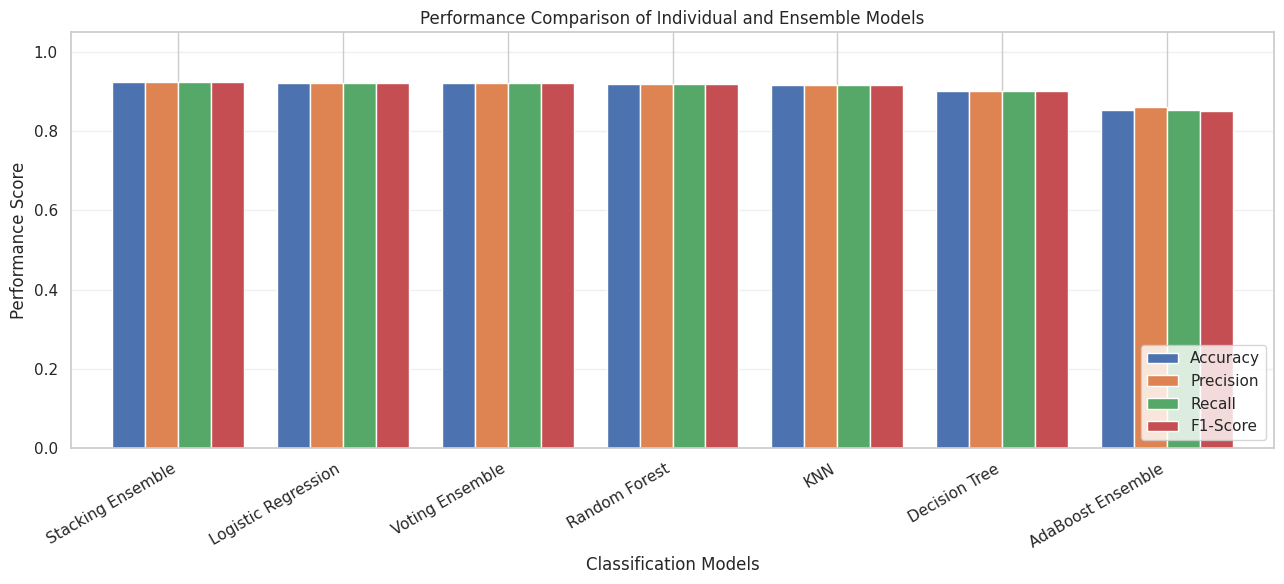

In [ ]:

# Visual comparison of all classification metrics
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

comparison_df.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(13, 6),
    width=0.8
)

plt.title("Performance Comparison of Individual and Ensemble Models")
plt.xlabel("Classification Models")
plt.ylabel("Performance Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=30, ha='right')
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


**Observation:** The graph compares the predictive performance of individual and ensemble classifiers using four evaluation metrics. Higher values indicate better classification performance.

**Best performing model**

In [ ]:

# Identify the best model using weighted F1-score
best_model_name = comparison_df.iloc[0]['Model']
best_f1_score = comparison_df.iloc[0]['F1-Score']

best_model_map = {
    'Decision Tree': dt_model,
    'Random Forest': rf_model,
    'KNN': knn_model,
    'Logistic Regression': lr_model,
    'Stacking Ensemble': stacking_model,
    'AdaBoost Ensemble': adaboost_model,
    'Voting Ensemble': voting_model
}

best_model = best_model_map[best_model_name]

print("BEST PERFORMING MODEL")
print("=" * 40)
print("Model:", best_model_name)
print(f"Weighted F1-Score: {best_f1_score:.4f}")


BEST PERFORMING MODEL
Model: Stacking Ensemble
Weighted F1-Score: 0.9244


**Confusion matrix of the best model**

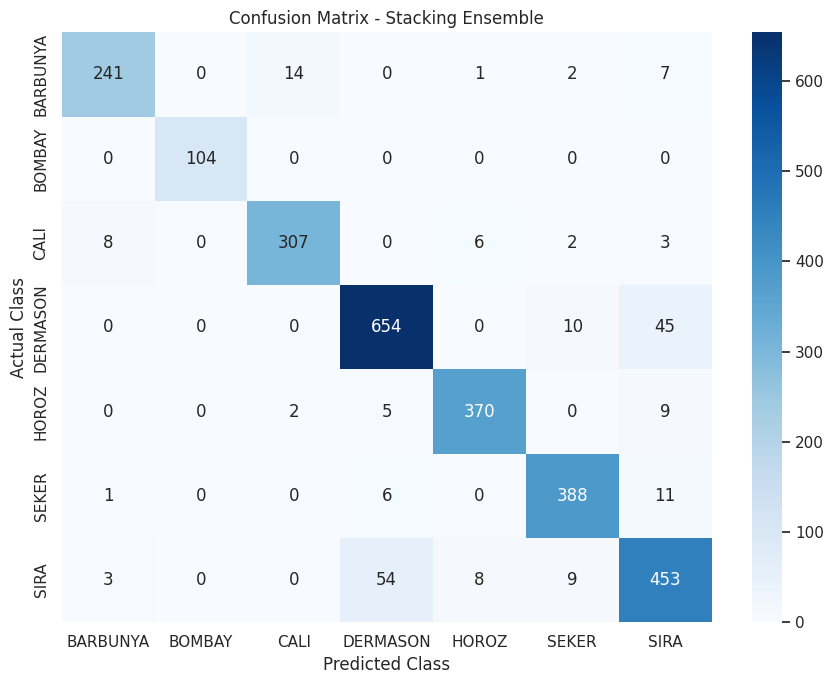

In [ ]:

# Predictions from the best model
best_predictions = best_model.predict(X_test)

# Generate confusion matrix
cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=best_model.classes_
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()


**Observation:** The diagonal elements represent correctly classified bean samples, while the off-diagonal elements represent misclassifications. A strong classifier will have higher values along the diagonal.

**Classification report**

In [ ]:

# Detailed classification report
print("CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        best_predictions,
        zero_division=0
    )
)


CLASSIFICATION REPORT
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.91      0.93       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.95      0.94      0.95       326
    DERMASON       0.91      0.92      0.92       709
       HOROZ       0.96      0.96      0.96       386
       SEKER       0.94      0.96      0.95       406
        SIRA       0.86      0.86      0.86       527

    accuracy                           0.92      2723
   macro avg       0.94      0.94      0.94      2723
weighted avg       0.92      0.92      0.92      2723



**Explanation:** The classification report provides class-wise Precision, Recall, F1-score and Support. It helps evaluate how effectively the selected model classifies each bean variety, including minority classes.

**Macro and weighted F1-score comparison**

In [ ]:

# Compare macro and weighted F1-scores
f1_comparison = []

for name, model in best_model_map.items():

    predictions = model.predict(X_test)

    f1_comparison.append({
        'Model': name,
        'Macro F1': f1_score(
            y_test, predictions, average='macro'
        ),
        'Weighted F1': f1_score(
            y_test, predictions, average='weighted'
        )
    })

f1_df = pd.DataFrame(f1_comparison)

display(f1_df.sort_values(
    by='Macro F1',
    ascending=False
).round(4))


,Model,Macro F1,Weighted F1
4,Stacking Ensemble,0.9373,0.9244
6,Voting Ensemble,0.9341,0.9212
3,Logistic Regression,0.9335,0.9216
1,Random Forest,0.9321,0.9198
2,KNN,0.9293,0.9168
0,Decision Tree,0.9162,0.9024
5,AdaBoost Ensemble,0.8091,0.8504


**Observation:** Macro F1 treats all classes equally, while weighted F1 considers the number of samples in each class. Comparing both scores helps identify whether model performance is consistent across all bean varieties.

**Feature importance analysis**

We will use Random Forest to identify which features contribute most to classification.

TOP 10 IMPORTANT FEATURES


,Feature,Importance
14,ShapeFactor3,0.1064
1,Perimeter,0.0898
11,Compactness,0.0879
12,ShapeFactor1,0.0839
3,MinorAxisLength,0.0804
2,MajorAxisLength,0.0769
6,ConvexArea,0.0721
5,Eccentricity,0.0629
0,Area,0.0616
7,EquivDiameter,0.0596


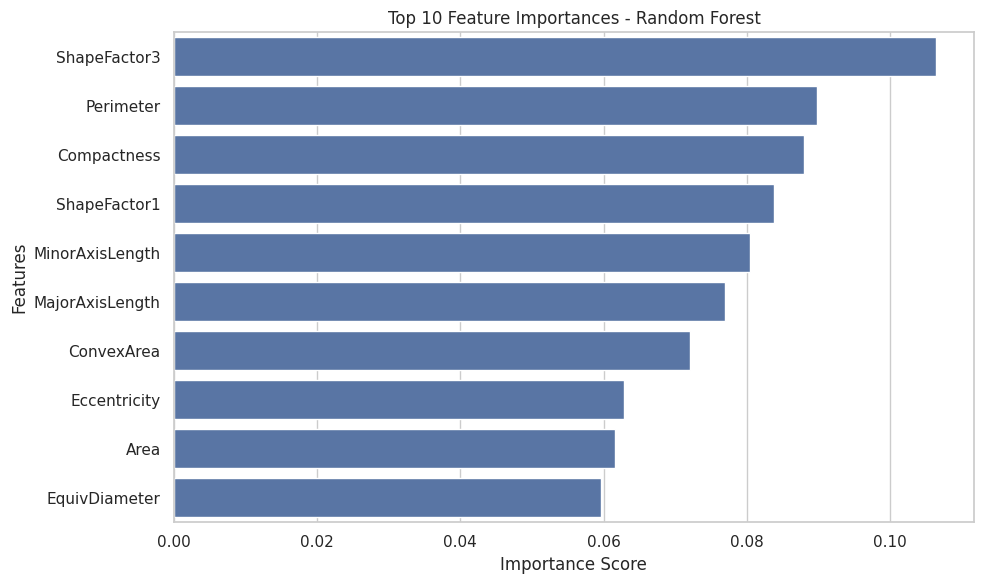

In [ ]:

# Extract Random Forest feature importance
feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print("TOP 10 IMPORTANT FEATURES")
display(feature_importance.head(10).round(4))

# Plot feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance.head(10),
    x='Importance',
    y='Feature'
)

plt.title("Top 10 Feature Importances - Random Forest")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()


**Observation:** Feature importance indicates which bean measurements contribute most to the Random Forest model's predictions. It provides insight into the characteristics useful for distinguishing bean varieties.

**Findings and interpretation:**

**Automatic performance summary**

In [ ]:

# Generate automatic findings
print("EXPERIMENTAL FINDINGS")
print("=" * 55)

print("\n1. Best Performing Model:")
print(best_model_name)

print("\n2. Highest Accuracy:")
accuracy_best = comparison_df.loc[
    comparison_df['Accuracy'].idxmax()
]
print(
    accuracy_best['Model'],
    ":", round(accuracy_best['Accuracy'], 4)
)

print("\n3. Highest Weighted F1-Score:")
f1_best = comparison_df.loc[
    comparison_df['F1-Score'].idxmax()
]
print(
    f1_best['Model'],
    ":", round(f1_best['F1-Score'], 4)
)

print("\n4. Highest Precision:")
precision_best = comparison_df.loc[
    comparison_df['Precision'].idxmax()
]
print(
    precision_best['Model'],
    ":", round(precision_best['Precision'], 4)
)

print("\n5. Highest Recall:")
recall_best = comparison_df.loc[
    comparison_df['Recall'].idxmax()
]
print(
    recall_best['Model'],
    ":", round(recall_best['Recall'], 4)
)

print("\n6. Model Comparison:")
print(
    "Individual Classifiers:",
    comparison_df[
        comparison_df['Model'].isin(base_models.keys())
    ]['F1-Score'].mean().round(4),
    "Average Weighted F1"
)

print(
    "Ensemble Classifiers:",
    comparison_df[
        comparison_df['Model'].isin([
            'Stacking Ensemble',
            'AdaBoost Ensemble',
            'Voting Ensemble'
        ])
    ]['F1-Score'].mean().round(4),
    "Average Weighted F1"
)


EXPERIMENTAL FINDINGS

1. Best Performing Model:
Stacking Ensemble

2. Highest Accuracy:
Stacking Ensemble : 0.9243

3. Highest Weighted F1-Score:
Stacking Ensemble : 0.9244

4. Highest Precision:
Stacking Ensemble : 0.9246

5. Highest Recall:
Stacking Ensemble : 0.9243

6. Model Comparison:
Individual Classifiers: 0.9152 Average Weighted F1
Ensemble Classifiers: 0.8987 Average Weighted F1


**Comparative analysis of ensemble techniques**

ENSEMBLE TECHNIQUE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Stacking Ensemble,0.9243,0.9246,0.9243,0.9244
2,Voting Ensemble,0.9214,0.9214,0.9214,0.9212
6,AdaBoost Ensemble,0.8535,0.8614,0.8535,0.8504


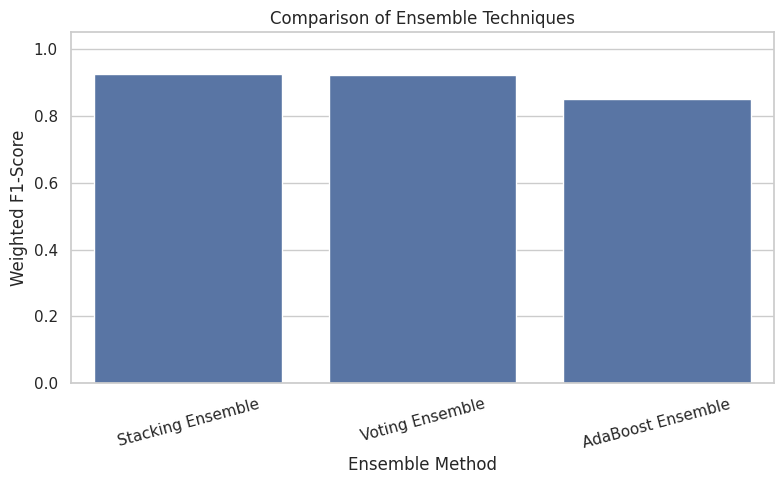

In [ ]:

# Compare the three ensemble techniques
ensemble_comparison = comparison_df[
    comparison_df['Model'].isin([
        'Stacking Ensemble',
        'AdaBoost Ensemble',
        'Voting Ensemble'
    ])
].copy()

print("ENSEMBLE TECHNIQUE COMPARISON")
display(ensemble_comparison.round(4))

# Plot weighted F1-score
plt.figure(figsize=(8, 5))

sns.barplot(
    data=ensemble_comparison,
    x='Model',
    y='F1-Score'
)

plt.title("Comparison of Ensemble Techniques")
plt.xlabel("Ensemble Method")
plt.ylabel("Weighted F1-Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


**Observation:** This comparison identifies which ensemble technique performs better on the Dry Bean dataset. Stacking can learn how to combine base-model outputs, AdaBoost focuses on previously misclassified samples, and Voting combines independent predictions.

---

**4. Applications of Ensemble Learning:**

Ensemble learning techniques can be applied in various real-world domains.

1. Agriculture: Classification of crop varieties, seed quality assessment, and disease detection.
2. Healthcare: Medical image classification and disease prediction.
3. Banking: Fraud detection and credit risk assessment.
4. E-commerce: Product categorization and customer behavior prediction.
5. Manufacturing: Quality inspection and defect detection.

**When to Use Each Ensemble Technique:**

**Stacking:**
Useful when multiple diverse classifiers provide complementary predictions and a meta-classifier can learn how to combine them.

**AdaBoost:**
Useful when weak learners perform better collectively through sequential correction of classification errors.

**Voting:**
Useful when multiple reasonably accurate classifiers are available and a simple combination of their predictions is desired.

---


**5. Ethical Considerations:**

1. Data Quality: Incorrect or inconsistent measurements can affect model predictions.
2. Class Imbalance: Unequal representation of bean varieties may result in lower prediction performance for minority classes.
3. Fair Evaluation: Training and testing data must be separated properly to avoid data leakage.
4. Transparency: Feature importance and classification reports should be examined to understand model behavior.
5. Responsible Use: Model predictions should be validated before using them for agricultural or commercial decisions.
6. Reproducibility: Fixed random states and documented parameters help ensure consistent experimental results.

The model should be used as a decision-support tool rather than a complete replacement for expert assessment.

---


**6. Future Scope:**

1. Hyperparameter tuning can be performed using GridSearchCV or RandomizedSearchCV.
2. Additional ensemble methods such as Gradient Boosting, XGBoost, and LightGBM can be explored.
3. Class imbalance handling techniques such as SMOTE can be investigated.
4. Feature selection can be applied to identify the most relevant input variables.
5. Cross-validation can be used for more reliable model evaluation.
6. The trained model can be deployed as a web-based bean classification application using Streamlit or Flask.
7. Performance can be tested on external datasets to evaluate generalization.

---


**7. Conclusion:**

In this practical assignment, ensemble learning techniques were successfully implemented using the Dry Bean Dataset, which contains 13,611 observations, 16 numerical features, and seven bean categories.

Four individual classification algorithms, namely Decision Tree, Random Forest, K-Nearest Neighbors, and Logistic Regression, were implemented and evaluated.

Three ensemble techniques, namely Stacking, AdaBoost, and Hard Voting, were also implemented to study how combining multiple classifiers influences predictive performance.

The models were evaluated using Accuracy, Precision, Recall, and F1-score. Confusion matrices, classification reports, and graphical comparisons were used to analyze their performance.

The experimental results demonstrate that different ensemble techniques have different strengths depending on the characteristics of the dataset and the behavior of their base learners. The best-performing model was identified using the weighted F1-score.

Thus, the assignment successfully demonstrates the implementation, evaluation, and comparison of individual and ensemble classification algorithms. It also highlights the importance of model selection, reliable evaluation, and responsible application of machine learning techniques.



